In [1]:
import pandas as pd

Xtr = pd.read_csv("../data/X_train.csv")
Xte = pd.read_csv("../data/X_test.csv")
y_train = pd.read_csv("../data/y_train.csv").squeeze()
y_test = pd.read_csv("../data/y_test.csv").squeeze()

print(Xtr.shape, Xte.shape, y_train.shape, y_test.shape)

(3539, 232) (885, 232) (3539,) (885,)


In [2]:
#checking column names
for keyword in ["Debtor", "Tuition", "Scholarship", "financial", "attendance", "Curricular", "pass_rate"]:
    print(keyword, "→", [c for c in Xtr.columns if keyword.lower() in c.lower()])

Debtor → ['Debtor']
Tuition → ['Tuition fees up to date']
Scholarship → ['Scholarship holder']
financial → ['financial_pressure']
attendance → ['Daytime/evening attendance']
Curricular → ['Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)']
pass_rate → ['pass_rate_1st_sem']


In [3]:
financial_cols = ["Debtor", "Tuition fees up to date", "Scholarship holder", "financial_pressure"]

attendance_cols = ["Daytime/evening attendance",
                   "Curricular units 1st sem (enrolled)",
                   "Curricular units 1st sem (evaluations)",
                   "Curricular units 1st sem (approved)",
                   "Curricular units 1st sem (without evaluations)",
                   "pass_rate_1st_sem"]

# Keep only names that exist, and flag any that don't
for name, cols in [("financial", financial_cols), ("attendance", attendance_cols)]:
    missing = [c for c in cols if c not in Xtr.columns]
    print(name, "missing:", missing if missing else "none")

financial_cols = [c for c in financial_cols if c in Xtr.columns]
attendance_cols = [c for c in attendance_cols if c in Xtr.columns]

financial missing: none
attendance missing: none


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, accuracy_score

groups = {
    "Financial only": financial_cols,
    "Attendance/academic only": attendance_cols,
    "All features": list(Xtr.columns),
}

results = []
for name, cols in groups.items():
    model = LogisticRegression(max_iter=2000, class_weight="balanced")
    model.fit(Xtr[cols], y_train)
    preds = model.predict(Xte[cols])

    results.append({"Model": name,
                    "Features": len(cols),
                    "Accuracy": accuracy_score(y_test, preds),
                    "Macro F1": f1_score(y_test, preds, average="macro")})

    print(f"\n===== {name} =====")
    print(classification_report(y_test, preds))

results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df


===== Financial only =====
              precision    recall  f1-score   support

     Dropout       0.85      0.33      0.47       284
    Enrolled       0.22      0.79      0.34       159
    Graduate       0.79      0.35      0.49       442

    accuracy                           0.42       885
   macro avg       0.62      0.49      0.43       885
weighted avg       0.71      0.42      0.46       885


===== Attendance/academic only =====
              precision    recall  f1-score   support

     Dropout       0.77      0.59      0.67       284
    Enrolled       0.35      0.54      0.43       159
    Graduate       0.82      0.78      0.80       442

    accuracy                           0.68       885
   macro avg       0.65      0.64      0.63       885
weighted avg       0.72      0.68      0.69       885


===== All features =====
              precision    recall  f1-score   support

     Dropout       0.78      0.68      0.73       284
    Enrolled       0.38      0.57    

,Features,Accuracy,Macro F1
Model,,,
Financial only,4,0.421,0.432
Attendance/academic only,6,0.678,0.632
All features,232,0.697,0.658


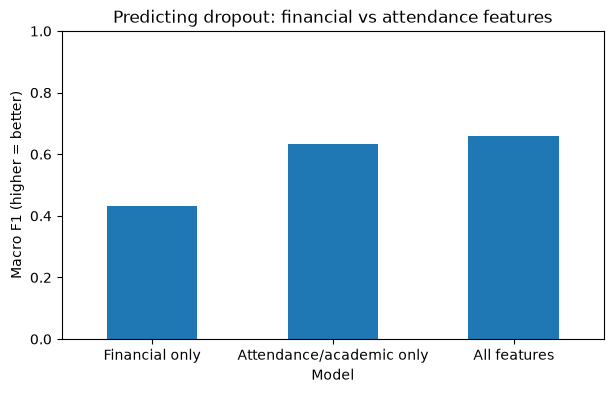

In [5]:
import matplotlib.pyplot as plt

results_df["Macro F1"].plot(kind="bar", rot=0, figsize=(7, 4),
                            title="Predicting dropout: financial vs attendance features")
plt.ylabel("Macro F1 (higher = better)")
plt.ylim(0, 1)
plt.show()

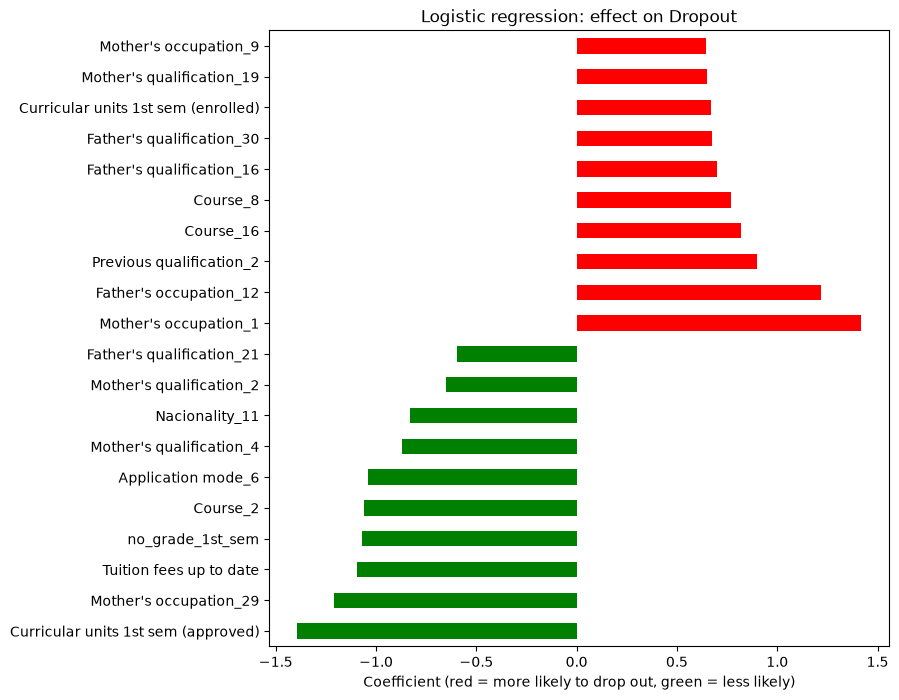

Curricular units 1st sem (approved)              -1.392
Tuition fees up to date                          -1.097
pass_rate_1st_sem                                -0.344
Debtor                                           -0.279
Curricular units 1st sem (evaluations)           -0.150
Curricular units 1st sem (without evaluations)   -0.119
Daytime/evening attendance                        0.203
Scholarship holder                                0.513
financial_pressure                                0.557
Curricular units 1st sem (enrolled)               0.671
dtype: float64

In [6]:
full = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xtr, y_train)

dropout_idx = list(full.classes_).index("Dropout")
coefs = pd.Series(full.coef_[dropout_idx], index=Xtr.columns)

# With 232 features, show the 10 strongest in each direction
top = pd.concat([coefs.nsmallest(10), coefs.nlargest(10)])
top.plot(kind="barh", figsize=(8, 8),
         color=["green" if v < 0 else "red" for v in top])
plt.title("Logistic regression: effect on Dropout")
plt.xlabel("Coefficient (red = more likely to drop out, green = less likely)")
plt.show()

# How the financial and attendance features compare specifically
coefs[financial_cols + attendance_cols].sort_values().round(3)

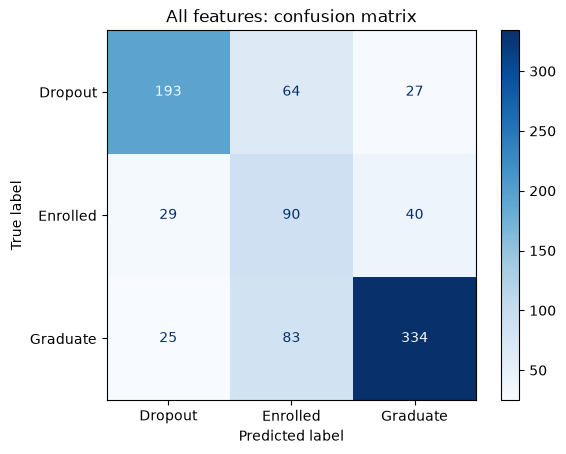

In [7]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(full, Xte, y_test, cmap="Blues")
plt.title("All features: confusion matrix")
plt.show()